In [1]:
%%time
dataset_name = "W27_only"
df_list = "BES_Panel|BES_reduced_with_na"

%matplotlib inline 
%run BES_header.py {dataset_name} {df_list}

global BES_label_list, BES_df_list

Toggle code

var_type (712, 13)
CPU times: total: 4.66 s
Wall time: 41.1 s


In [2]:
search(BES_reduced_with_na,"britishPride")

britishPride__Strongly agree    29867
dtype: int64

In [4]:
name = "britishPride__Strongly agree"
df, corr_type = make_corr_summary(BES_reduced_with_na, name)
display_corr(df, name, corr_type)

,r,p,N
scotRefID_The No side,0.610000,0.00,2519
britishness__Very strongly British,0.580000,0.00,29569
ukGovtEconImpactScot__Large positive impact,0.480000,0.00,2852
likeCon__Strongly like,0.450000,0.00,28834
ptvCon__Very likely,0.430000,0.00,7030
approveUKGovt__Strongly approve,0.410000,0.00,29140
handleGazaGov__Very well,0.410000,0.00,24394
leftRight__Right,0.410000,0.00,24265
likeSunak__Strongly like,0.410000,0.00,28925
englishness__Very strongly English,0.410000,0.00,29523


In [92]:
search(BES_reduced_with_na,"vote")[100:].head(50)

p_scot_list_vote_2011_Conservative                                                                                1827
p_scot_list_vote_2011_Liberal Democrat                                                                            1827
p_scot_list_vote_2011_Green Party                                                                                 1827
p_scot_const_vote_2016_I would/did not vote                                                                      10513
p_scot_const_vote_2016_Scottish National Party (SNP)                                                             10513
p_scot_const_vote_2016_Conservative                                                                              10513
p_scot_const_vote_2016_Labour                                                                                    10513
p_scot_const_vote_2016_Liberal Democrat                                                                          10513
p_scot_list_vote_2016_I would/did not vote      

In [37]:
search(BES_reduced_with_na,"al_scale|lr_scale|like")

turnoutUKGeneral__Very likely that I will vote     29646
likeBadenoch__Strongly like                        25632
likeStarmer__Strongly like                         29345
likeDavey__Strongly like                           24110
likeSwinney__Strongly like                          2776
likeFarage__Strongly like                          29319
likeRamsay__Strongly like                           5138
likeDenyer__Strongly like                           6386
likeCon__Strongly like                             29440
likeLab__Strongly like                             29463
likeLD__Strongly like                              28175
likeSNP__Strongly like                              2940
likePC__Strongly like                               1721
likeBrexitParty__Strongly like                     28818
likeGrn__Strongly like                             27810
riskPoverty__Very likely                           28804
riskUnemployment__Very likely                      27160
ptvCon__Very likely            

In [41]:
mask = (BES_Panel["al_scale"].notnull()) & (BES_Panel["lr_scale"].notnull()) & (BES_Panel["country"]=="England")
mask.sum()

21068

In [70]:
round(pd.crosstab(BES_Panel["p_housing"],BES_Panel["likeBrexitParty"],values=BES_Panel["wt"],aggfunc=sum,normalize='index')*100,2).astype(int)

likeBrexitParty,Strongly dislike,1,2,3,4,5,6,7,8,9,Strongly like,Don't know
p_housing,,,,,,,,,,,,
Own – outright,33,4,4,4,4,9,6,7,7,4,8,4
Own – with a mortgage,45,5,4,4,3,6,4,4,4,2,5,7
"Own (part-own) – through shared ownership scheme (i.e. pay part mortgage, part rent)",49,3,3,3,5,5,3,7,3,0,3,11
Rent – from a private landlord,47,3,4,4,2,7,3,4,3,1,5,10
Rent – from my local authority,28,3,4,4,4,9,5,6,6,3,10,12
Rent – from a housing association,35,3,3,4,3,8,4,5,6,2,10,12
"Neither – I live with my parents, family or friends but pay some rent to them",47,5,3,4,3,7,4,4,2,2,4,10
"Neither – I live rent-free with my parents, family or friends",51,5,3,3,3,6,3,2,2,1,3,12
Other,48,5,3,5,2,7,3,6,3,1,5,8


In [40]:
(BES_Panel["country"]=="England")

id
18        False
24         True
30         True
31        False
33         True
          ...  
123795     True
123796     True
123797     True
123798     True
123799     True
Name: country, Length: 30342, dtype: bool

In [23]:
((BES_reduced_with_na["al_scale__Authoritarian"]/10)-1 ).describe()

count    26542.000000
mean         0.252268
std          0.464990
min         -1.000000
25%         -0.100000
50%          0.300000
75%          0.600000
max          1.000000
Name: al_scale__Authoritarian, dtype: float64

In [45]:
((BES_reduced_with_na["al_scale__Authoritarian"]/10)-1 )

id
18       -1.0
24       -0.2
30        0.4
31        0.5
33       -0.1
         ... 
123795   -0.3
123796   -0.1
123797    0.7
123798    0.7
123799    0.8
Name: al_scale__Authoritarian, Length: 30342, dtype: float64

In [46]:
pan_dataset_values = pd.read_pickle(BES_small_data_files+"pan_dataset_allr_valuesW19.zip",compression='zip')

In [48]:

index_overlap = list(set(BES_Panel.index).intersection(set(pan_dataset_values.index)))
BES_reduced_with_na["al_scale_uni"] = np.nan
BES_reduced_with_na.loc[index_overlap,"al_scale_uni"] = (pan_dataset_values.loc[index_overlap,"Social: Liberalism(0) <-> Conservatism(200){uniform}"]-100)/100
BES_reduced_with_na["lr_scale_uni"] = np.nan
BES_reduced_with_na.loc[index_overlap,"lr_scale_uni"] = (pan_dataset_values.loc[index_overlap,"Economic: Left(0) <-> Right(200){uniform}"]-100)/100




In [55]:
from collections import OrderedDict
from symfit import Poly, variables, parameters, Model, Fit
import matplotlib as mpl
df_var_temp = pd.read_pickle( "df_var.zip" , compression='zip' )



x, y, z = variables('x, y, z')
c1, c2, c3 = parameters('c1, c2, c3')
# Make a polynomial. Note the `as_expr` to make it symfit friendly.
model_dict = {
    z: Poly( {(1, 0): c1, (0, 1): c2, (0,0):c3 }, x ,y).as_expr()
}
model = Model(model_dict)
granularity = 200
bound_box = 50
wave=30
like_or_ptv = "like"

def get_current_party(party,wave,like_or_ptv):
    replace_dict_W15 = {"CON":"Con","LAB":"Lab","LD":"LD","GP":"Grn","REFUK":"BrexitParty"}  
    replace_dict_pre_W15 = {"CON":"Con","LAB":"Lab","LD":"LD","GP":"Grn","REFUK":"UKIP"}  
    if wave>=15:
        return like_or_ptv+replace_dict_W15[party]+"W"+str(wave)
    else:
        return like_or_ptv+replace_dict_pre_W15[party]+"W"+str(wave)   

# Generate example data
x_vec = np.linspace(-1, 1, num=granularity)
y_vec = np.linspace(-1, 1, num=granularity)
xdata, ydata = np.meshgrid(x_vec, y_vec)

party_list = ["CON","LAB","LD","GP","REFUK"]
like_fit_df = pd.DataFrame(index=BES_reduced_with_na.index)
for party_var in party_list:
    
    current_party = get_current_party(party_var,wave,like_or_ptv)
    
    if current_party in df_var_temp.index:

        party_params = OrderedDict()
        party_params['c1'] = df_var_temp.loc[current_party]["c1"]
        party_params['c2'] = df_var_temp.loc[current_party]["c2"]
        party_params['c3'] = df_var_temp.loc[current_party]["c3"]
        
    steepness = df_var_temp.loc[current_party]["steepness"]  
    
    zfit = model(x=((BES_reduced_with_na["al_scale__Authoritarian"]/10)-1 ),
                 y=((BES_reduced_with_na["lr_scale__Right"]/10)-1 ), **party_params).z
    like_fit_df[party_var] = zfit.flatten()

In [ ]:
    # zfit = model(x=BES_reduced_with_na["al_scale_uni"],
    #              y=BES_reduced_with_na["lr_scale_uni"], **party_params).z

In [53]:
# wave specific al_scale

for party in ["Con","Lab","Grn","LD","BrexitParty"]:
    print( party )
    print( like_fit_df[mask].corrwith(BES_reduced_with_na["like"+party+"__Strongly like"][mask]).sort_values(ascending=False) )


Con
CON      0.577110
REFUK    0.464961
LD      -0.443679
LAB     -0.501088
GP      -0.537549
dtype: float64
Lab
LAB      0.394099
LD       0.391451
GP       0.387061
CON     -0.337460
REFUK   -0.393712
dtype: float64
Grn
GP       0.459189
LAB      0.451703
LD       0.430377
CON     -0.438463
REFUK   -0.439180
dtype: float64
LD
LAB      0.324279
LD       0.324046
GP       0.316916
CON     -0.272896
REFUK   -0.325237
dtype: float64
BrexitParty
REFUK    0.558344
CON      0.473511
GP      -0.546370
LD      -0.555775
LAB     -0.557720
dtype: float64


In [71]:
# pan dataset values
party_replace_dict = {"Con":"CON","Lab":"LAB","Grn":"GP","LD":"LD","BrexitParty":"REFUK"}

for party in ["Con","Lab","Grn","LD","BrexitParty"]:
    print( party )
    print( like_fit_df[mask].corrwith(BES_reduced_with_na["like"+party+"__Strongly like"][mask]).sort_values(ascending=False) )
    BES_reduced_with_na["fitted_like"+party] = like_fit_df[party_replace_dict[party]]
    BES_reduced_with_na["fitted_like_gap"+party] = like_fit_df[party_replace_dict[party]] - BES_reduced_with_na["like"+party+"__Strongly like"]

Con
CON      0.577110
REFUK    0.464961
LD      -0.443679
LAB     -0.501088
GP      -0.537549
dtype: float64
Lab
LAB      0.394099
LD       0.391451
GP       0.387061
CON     -0.337460
REFUK   -0.393712
dtype: float64
Grn
GP       0.459189
LAB      0.451703
LD       0.430377
CON     -0.438463
REFUK   -0.439180
dtype: float64
LD
LAB      0.324279
LD       0.324046
GP       0.316916
CON     -0.272896
REFUK   -0.325237
dtype: float64
BrexitParty
REFUK    0.558344
CON      0.473511
GP      -0.546370
LD      -0.555775
LAB     -0.557720
dtype: float64


In [74]:
like_fit_df[party_replace_dict[party]].describe()

count    25075.000000
mean         3.567941
std          1.363640
min         -0.324003
25%          2.683321
50%          3.798224
75%          4.607026
max          6.697978
Name: REFUK, dtype: float64

In [75]:
BES_reduced_with_na["like"+party+"__Strongly like"].describe()

count    28818.000000
mean         3.135714
std          3.580262
min          0.000000
25%          0.000000
50%          1.000000
75%          6.000000
max         10.000000
Name: likeBrexitParty__Strongly like, dtype: float64

In [34]:
like_fit_df.corrwith(BES_reduced_with_na["likeLab__Strongly like"])

CON     -0.311747
LAB      0.367714
LD       0.366950
GP       0.359964
REFUK   -0.368442
dtype: float64

In [35]:
like_fit_df.corrwith(BES_reduced_with_na["likeGrn__Strongly like"])

CON     -0.442080
LAB      0.455858
LD       0.435159
GP       0.462994
REFUK   -0.443726
dtype: float64

In [36]:
like_fit_df.corrwith(BES_reduced_with_na["likeLD__Strongly like"])

CON     -0.251754
LAB      0.304113
LD       0.305879
GP       0.295749
REFUK   -0.306290
dtype: float64

In [38]:
like_fit_df.corrwith(BES_reduced_with_na["likeBrexitParty__Strongly like"])

CON      0.476858
LAB     -0.557090
LD      -0.554572
GP      -0.546606
REFUK    0.557282
dtype: float64

In [57]:
BES_reduced_with_na.columns

Index(['turnoutUKGeneral__Very likely that I will vote',
       'partyIdStrength__Not very strong',
       'polAttention__Pay a great deal of attention',
       'pidWeThey__Strongly agree', 'pidInterestedOthers__Strongly agree',
       'pidCriticiseParty__Strongly agree', 'pidCommonParty__Strongly agree',
       'pidConnected__Strongly agree', 'pidPraiseGood__Strongly agree',
       'pidWeTheyb__Strongly agree',
       ...
       'selfOccStatus_An employee', 'selfOccEmployees_I have employees',
       'selfOccSupervise_Yes', 'al_scale_uni', 'lr_scale_uni',
       'fitted_likeCon', 'fitted_likeLab', 'fitted_likeGrn', 'fitted_likeLD',
       'fitted_likeBrexitParty'],
      dtype='object', length=850)

In [106]:
stub_vars = \
["genElecTurnoutRetro","generalElectionVote","voted_ge_2024","euRefVote","p_eurefvote","p_eurefturnout","euRefDoOver","eurefTurnoutRetro",
 "turnoutUKGeneral","recallVote","voted2015",
 "eurefFinal","goodConductEURef","negotiationSpecifics","euRefExpectation","euRefCertainty","certaintyUKLeave","certaintyUKRemain",
     "campaigninfoLeave","campaigninfoRemain",# opinion about future votes, but highyl Leave/remain correlated
     "leaveTone","remainTone","proConRemain","proConLeave","betterDealEU",
 "p_past_vote","p_turnout","profile_past_vote","profile_turnout","profile_eurefturnout",
 "voteMethoda","voteMethodb","voteMethod","attemptTurnout","postalTurnout","postalApply",
     "mayorTurnout","euroElectionVote","euroTurnout","voteMethodEurope",
 "generalElectionCertainty","decidedVote", #how certain are you of your vote - strong predictor of non-voting / decided vote already
 "regretsIHaveAFew","reasonForVote","generalElectionVoteNonVoter","askedForId","disapprovalVote","normPartyVote","reasonNonVoter",
 "partyContact","participation","changeView","debate(One|Two|Three|Four|Five|Six|Seven|Eight)Watch", # campaign fx
 "noChanceCoalition","(lab|con)Partner","hungParliament",
 "voteMakesDifference", # in your local area -> marginality/strat voting
 "smallPartyWastedVote","singlePartyEffective","difficultBlameCoalition","coalitionInTune","coalitionDontDeliver",
 "partydiffconlab", # little-much diff between con and lab - questionable
 "approve(UK|Scot|Welsh)Govt",
 "change(CostLive|Crime|Immig|Economy|NHS|Education)(Lab|Con|Govt)",
 "pccVote","pccTurnout","localElection","localTurnout",
 "happyEULeave",# if we treating the Leave vote as like voting for a party ...
 "dutyToVote","dutyToVote2", # ???? are these too strong of a predictor for non-voting?
# socialPressure, normEU, electionInterest, euRefInterest ????
 
 "like","ptv","partyId","partyPreferred","bestOnMII", "leftRight", # self-positioning relative to parties
     "euID",
 "prefer(Con|Lab|Other)","majorityParty(Con|Lab|LD|Brexit)","bestPM",
 "(lab|con|govt)Handle","handleMII","handleGaza","ukGovtEconImpact","ukLastGovtEconImpact","govtNatSecuritySuccess","scotGovtHandle","welshGovtHandle",
     "handleCorona","handleCoronaLab","handleUkraine","handleUkraineLab","handleEUNegotiate","handleEUNegotiateLab",
     "trustScotGovt","trustWelshGovt",
 "benchCoronaUK",# does effectively look like a "do you like the current UK govt?"
 "satDem",# also feels a little too close to evaluation of current govt

 "creditLeave","blameLeave","socialIdentityGlobalLeave","socialIdentityGlobalRemain","approveEU", # bit unclear, but creditLeave_Farage strictly identified UKIP voters
 
 
 "immig(Con|Lab|LD|SNP|PC|Brexit|Green|TIG|UKIP)","redist(Con|Lab|LD|SNP|PC|Brexit|Green|TIG|UKIP)",
     "EUIntegration(Con|Lab|LD|SNP|PC|Brexit|Green|TIG|May|Corbyn|UKIP)",
     "achieve","successReduceInequality", "_Ideas", # covers achieveReduce<issue><party>, achieveInc<issue><party>
     "(con|lab|ld|snp|pc|brexit|grn)Trust","(con|lab|ld|snp|pc|brexit|grn)Competent",
     "winConstituency(Con|Lab|LD|UKIP|TIG|Brexit|Green|SNP|PC|Ind)", # one of the few that directly referenced Ind candidates
     "lr(Con|Lab|LD|UKIP|SNP|PC|greens|TIG|Brexit)","lr(Starmer|Sunak|Corbyn|Cameron)",
     "competent(May|Corbyn|Farron|Johnson|Sunak|Starmer|Sturgeon|Wood|Farage|Lucas)",
     "integrity(May|Corbyn|Farron|Johnson|Sunak|Starmer|Sturgeon|Wood|Farage|Lucas)",
     "taxSpend(Con|Lab|LD|UKIP|SNP|PC|Green|Brexit)",
     "(con|lab|brexit|brx|snp|pc|ld|grn|tig|ukip)LookAfter",
     "(con|lab|ld|snp|pc|ukip|tig|grn|brexit)United",
     "(con|lab|ld|snp|pc|ukip|grn)GovTrust",
     "(con|lab|ld|snp|pc|ukip|grn)Hope",
     "cvEcon(Con|Lab|LD|SNP|PC|Green|Brexit)",
     "responsibleDebt(Conservatives|LiberalDemocrats|Labour)|responsible(Econ|NHS|Education|CostLive|Immig|Crime)",
     "certaintyEU(Con|Lab|LD|UKIP|Green|SNP|PC)",
     "(con|lab|ld|snp|pc|ukip|grn)(Angry|Hope|Fear|Pride|None)",
     "(ld|lab|con|snp|plaid|cabinet)Support",
     "enviroGrowth(Con|Lab|LD|SNP|PC|Green|Brexit)",
     "(con|lab|ld|ukip|green)Priorities",
     "(scot|welsh)ElectionVote|londonAssembly",
     "p_welsh","GE2024","VI2025",
 ]

In [79]:
BES_reduced_with_na.columns

Index(['turnoutUKGeneral__Very likely that I will vote',
       'partyIdStrength__Not very strong',
       'polAttention__Pay a great deal of attention',
       'pidWeThey__Strongly agree', 'pidInterestedOthers__Strongly agree',
       'pidCriticiseParty__Strongly agree', 'pidCommonParty__Strongly agree',
       'pidConnected__Strongly agree', 'pidPraiseGood__Strongly agree',
       'pidWeTheyb__Strongly agree',
       ...
       'fitted_likeCon', 'fitted_likeLab', 'fitted_likeGrn', 'fitted_likeLD',
       'fitted_likeBrexitParty', 'fitted_like_gapCon', 'fitted_like_gapLab',
       'fitted_like_gapGrn', 'fitted_like_gapLD',
       'fitted_like_gapBrexitParty'],
      dtype='object', length=855)

MSE: 4.28, MAE: 1.61, EV: 0.30, R2: 0.30
MSE: 4.03, MAE: 1.54, EV: 0.48, R2: 0.48
MSE: 4.31, MAE: 1.65, EV: 0.36, R2: 0.36
MSE: 4.28, MAE: 1.63, EV: 0.34, R2: 0.34
MSE: 4.56, MAE: 1.58, EV: 0.53, R2: 0.53


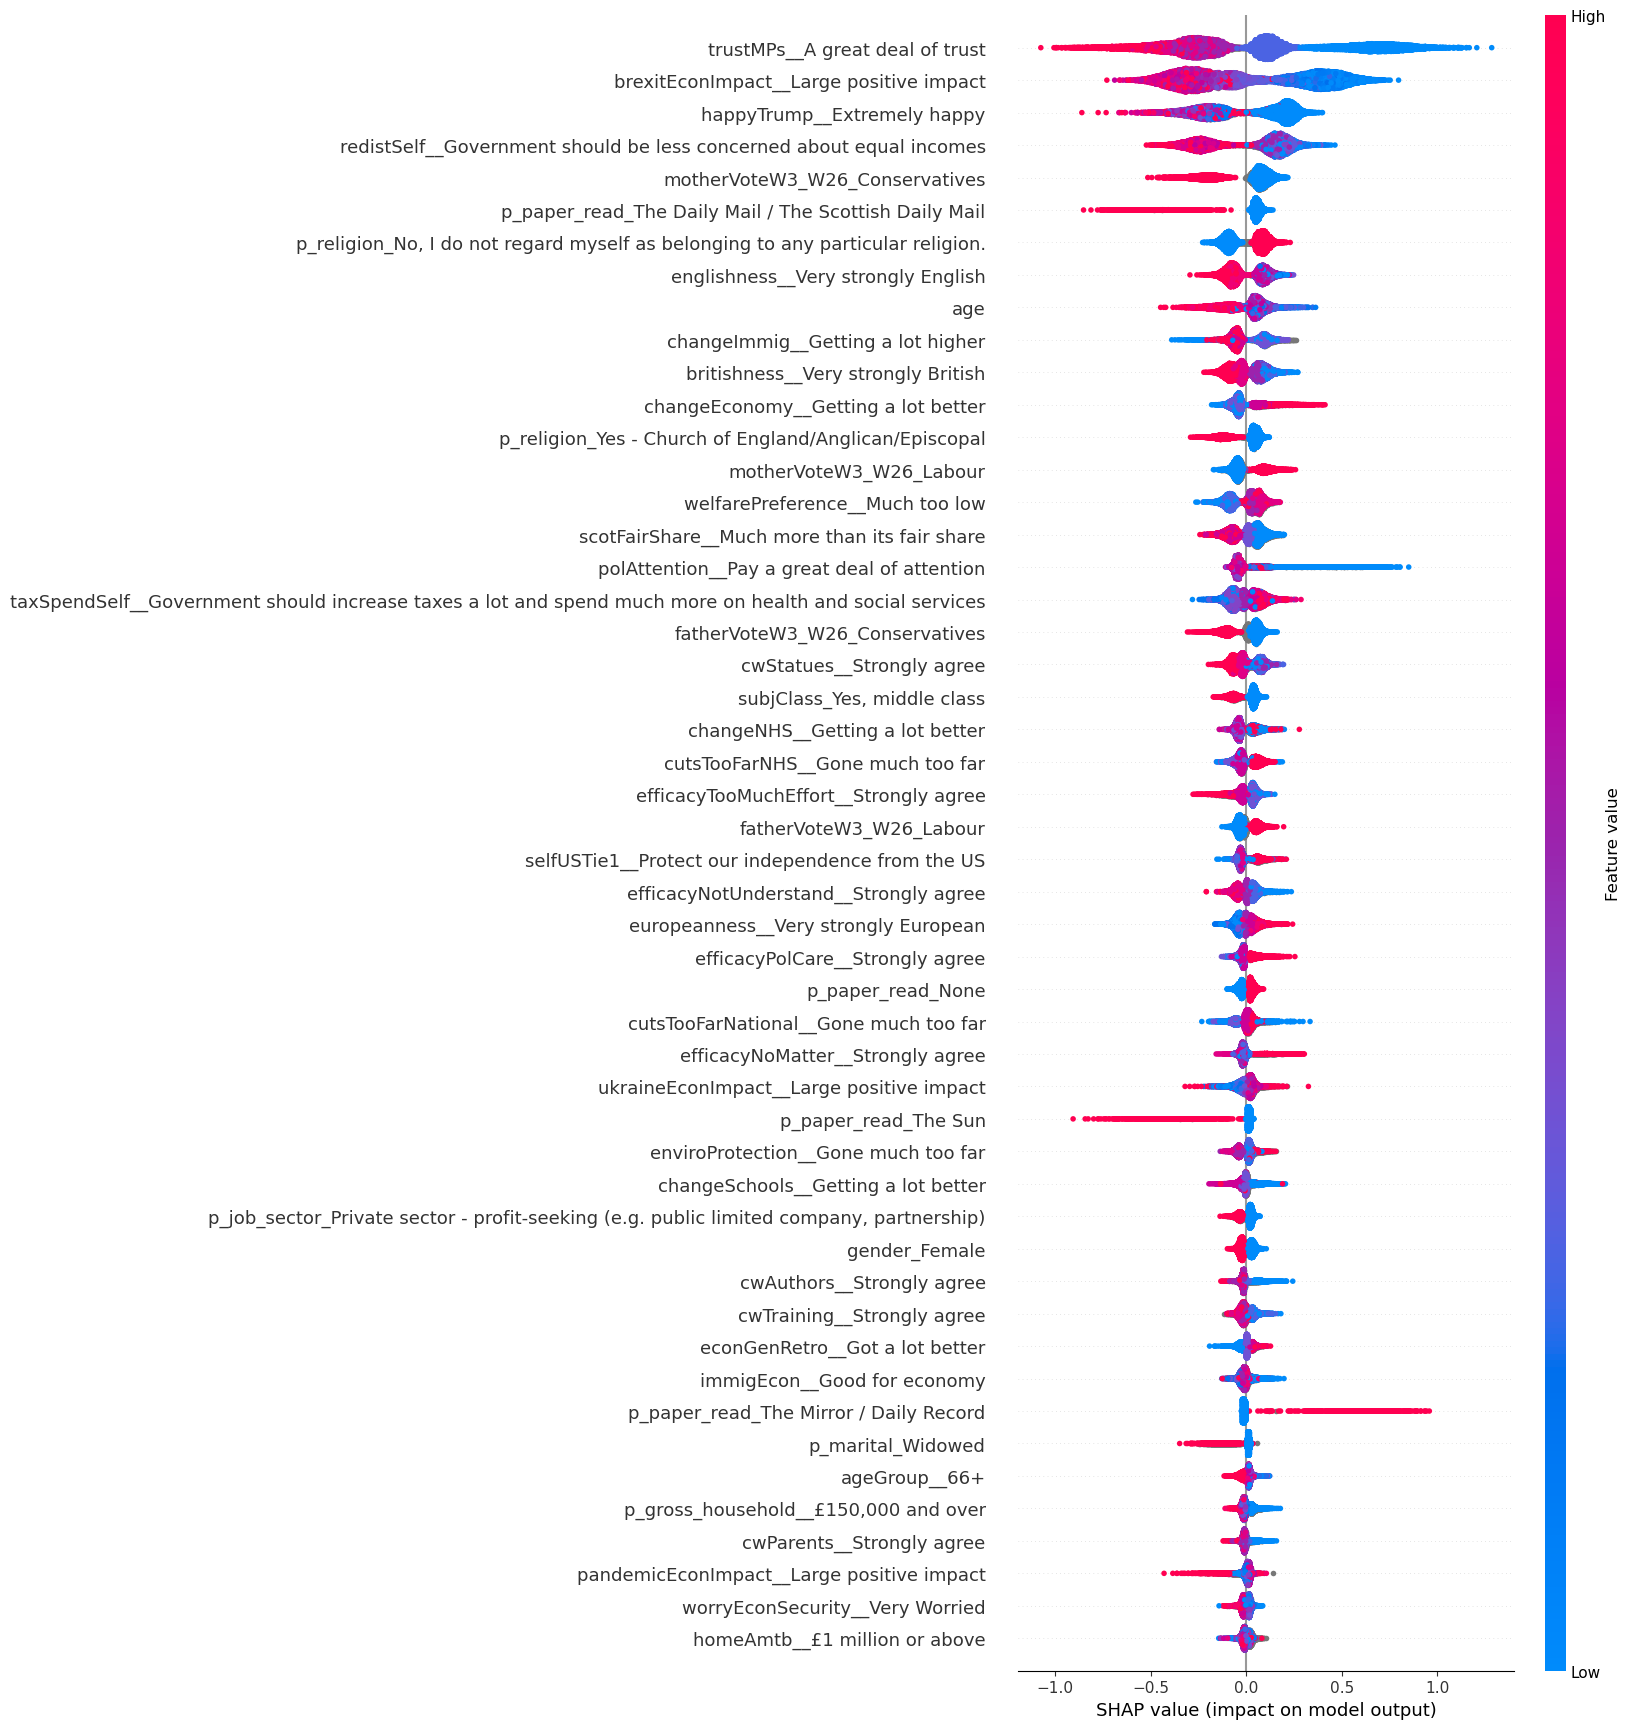

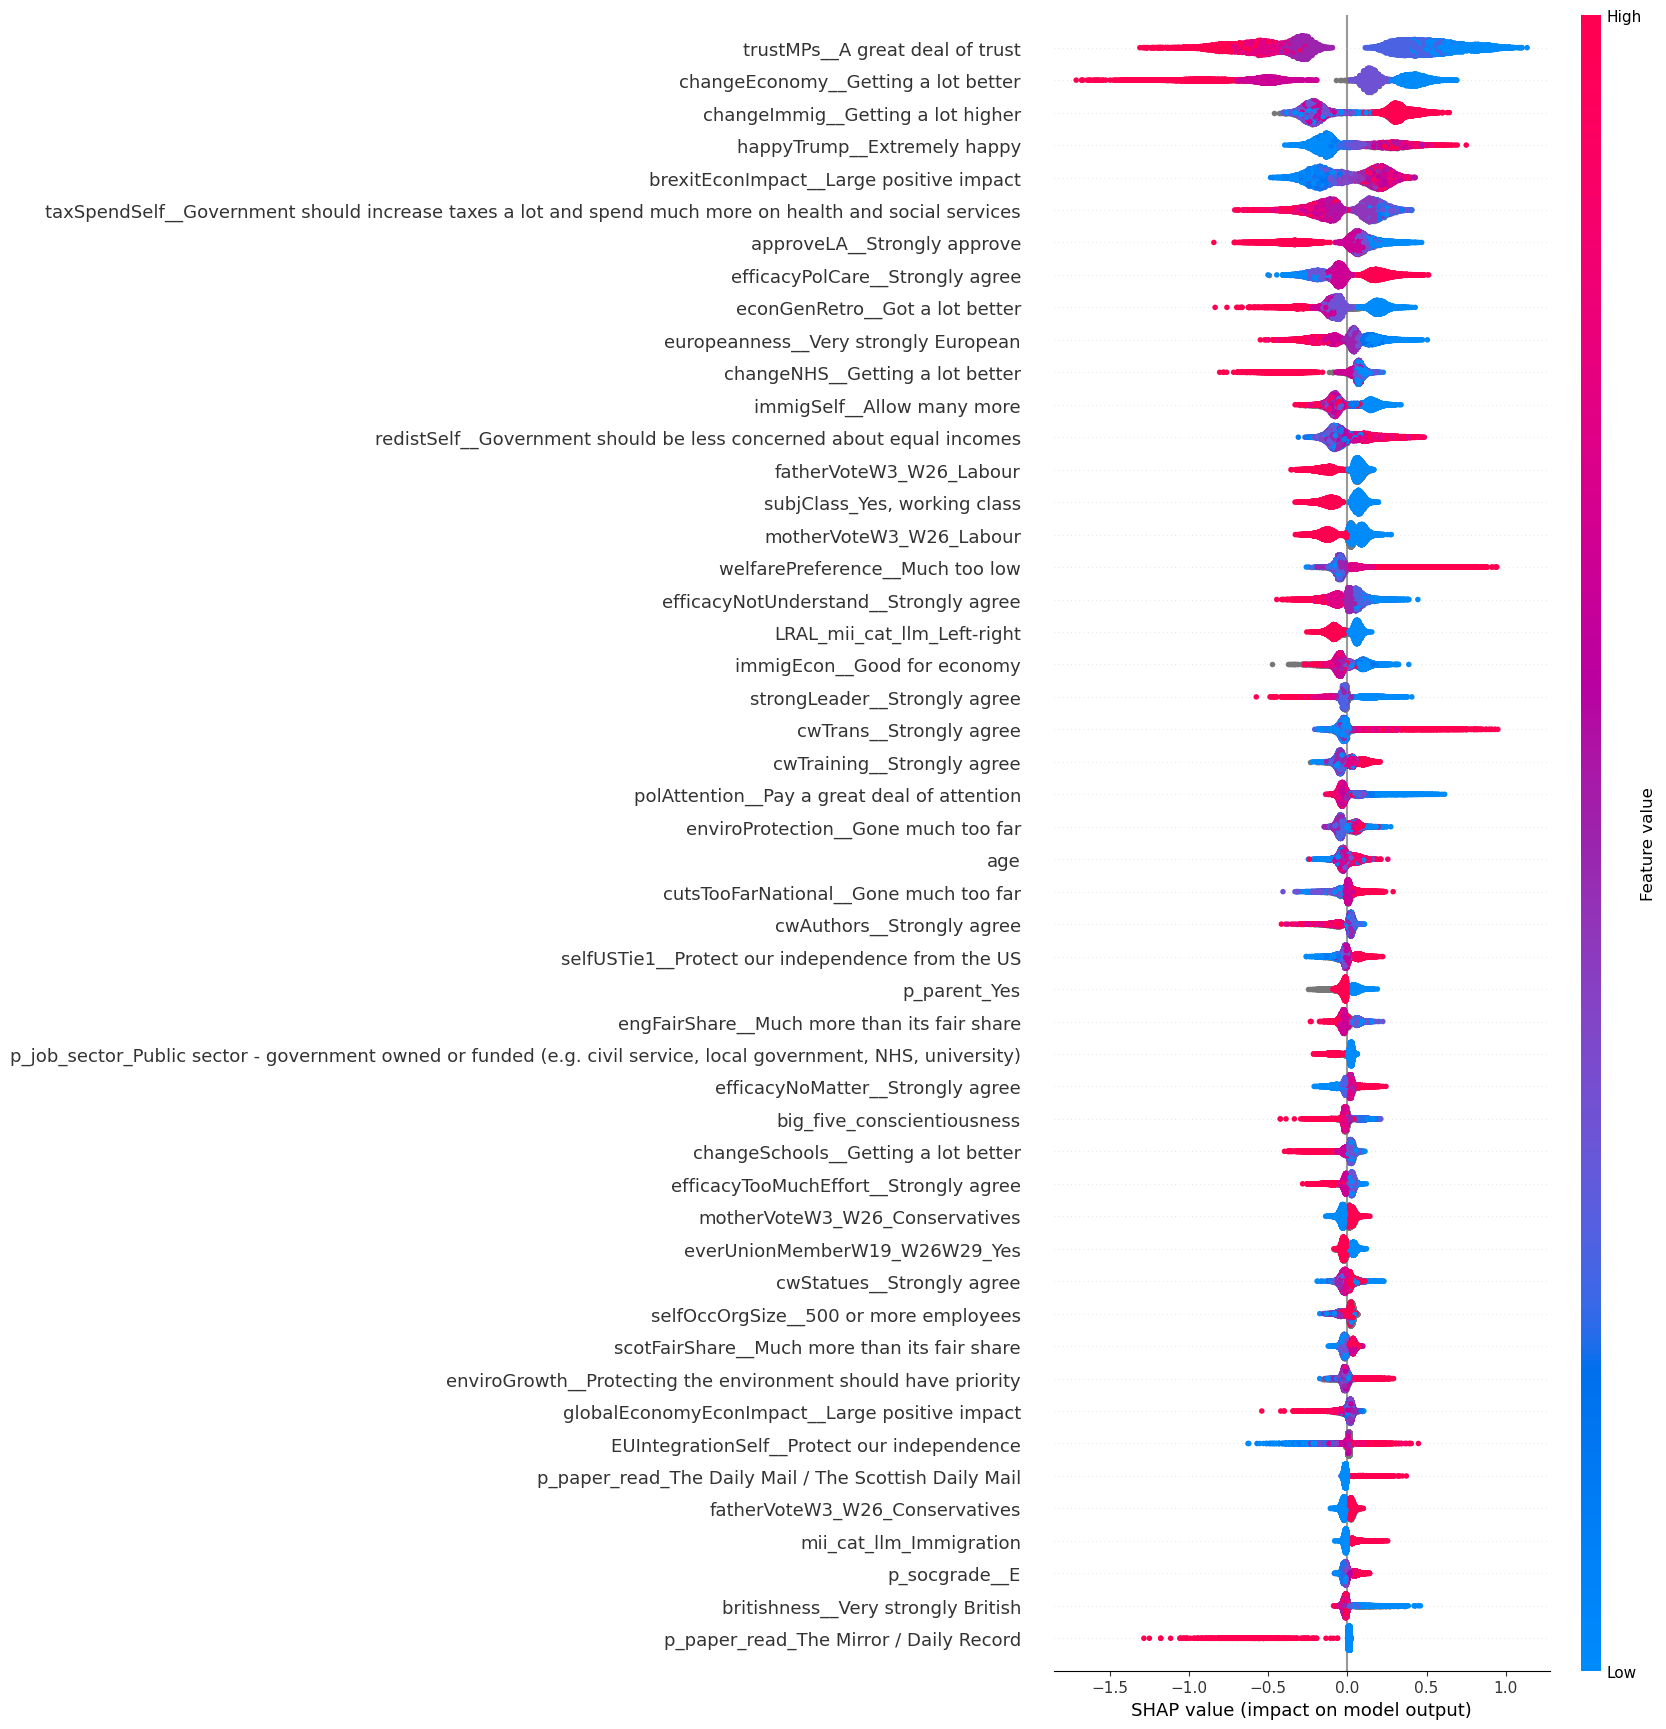

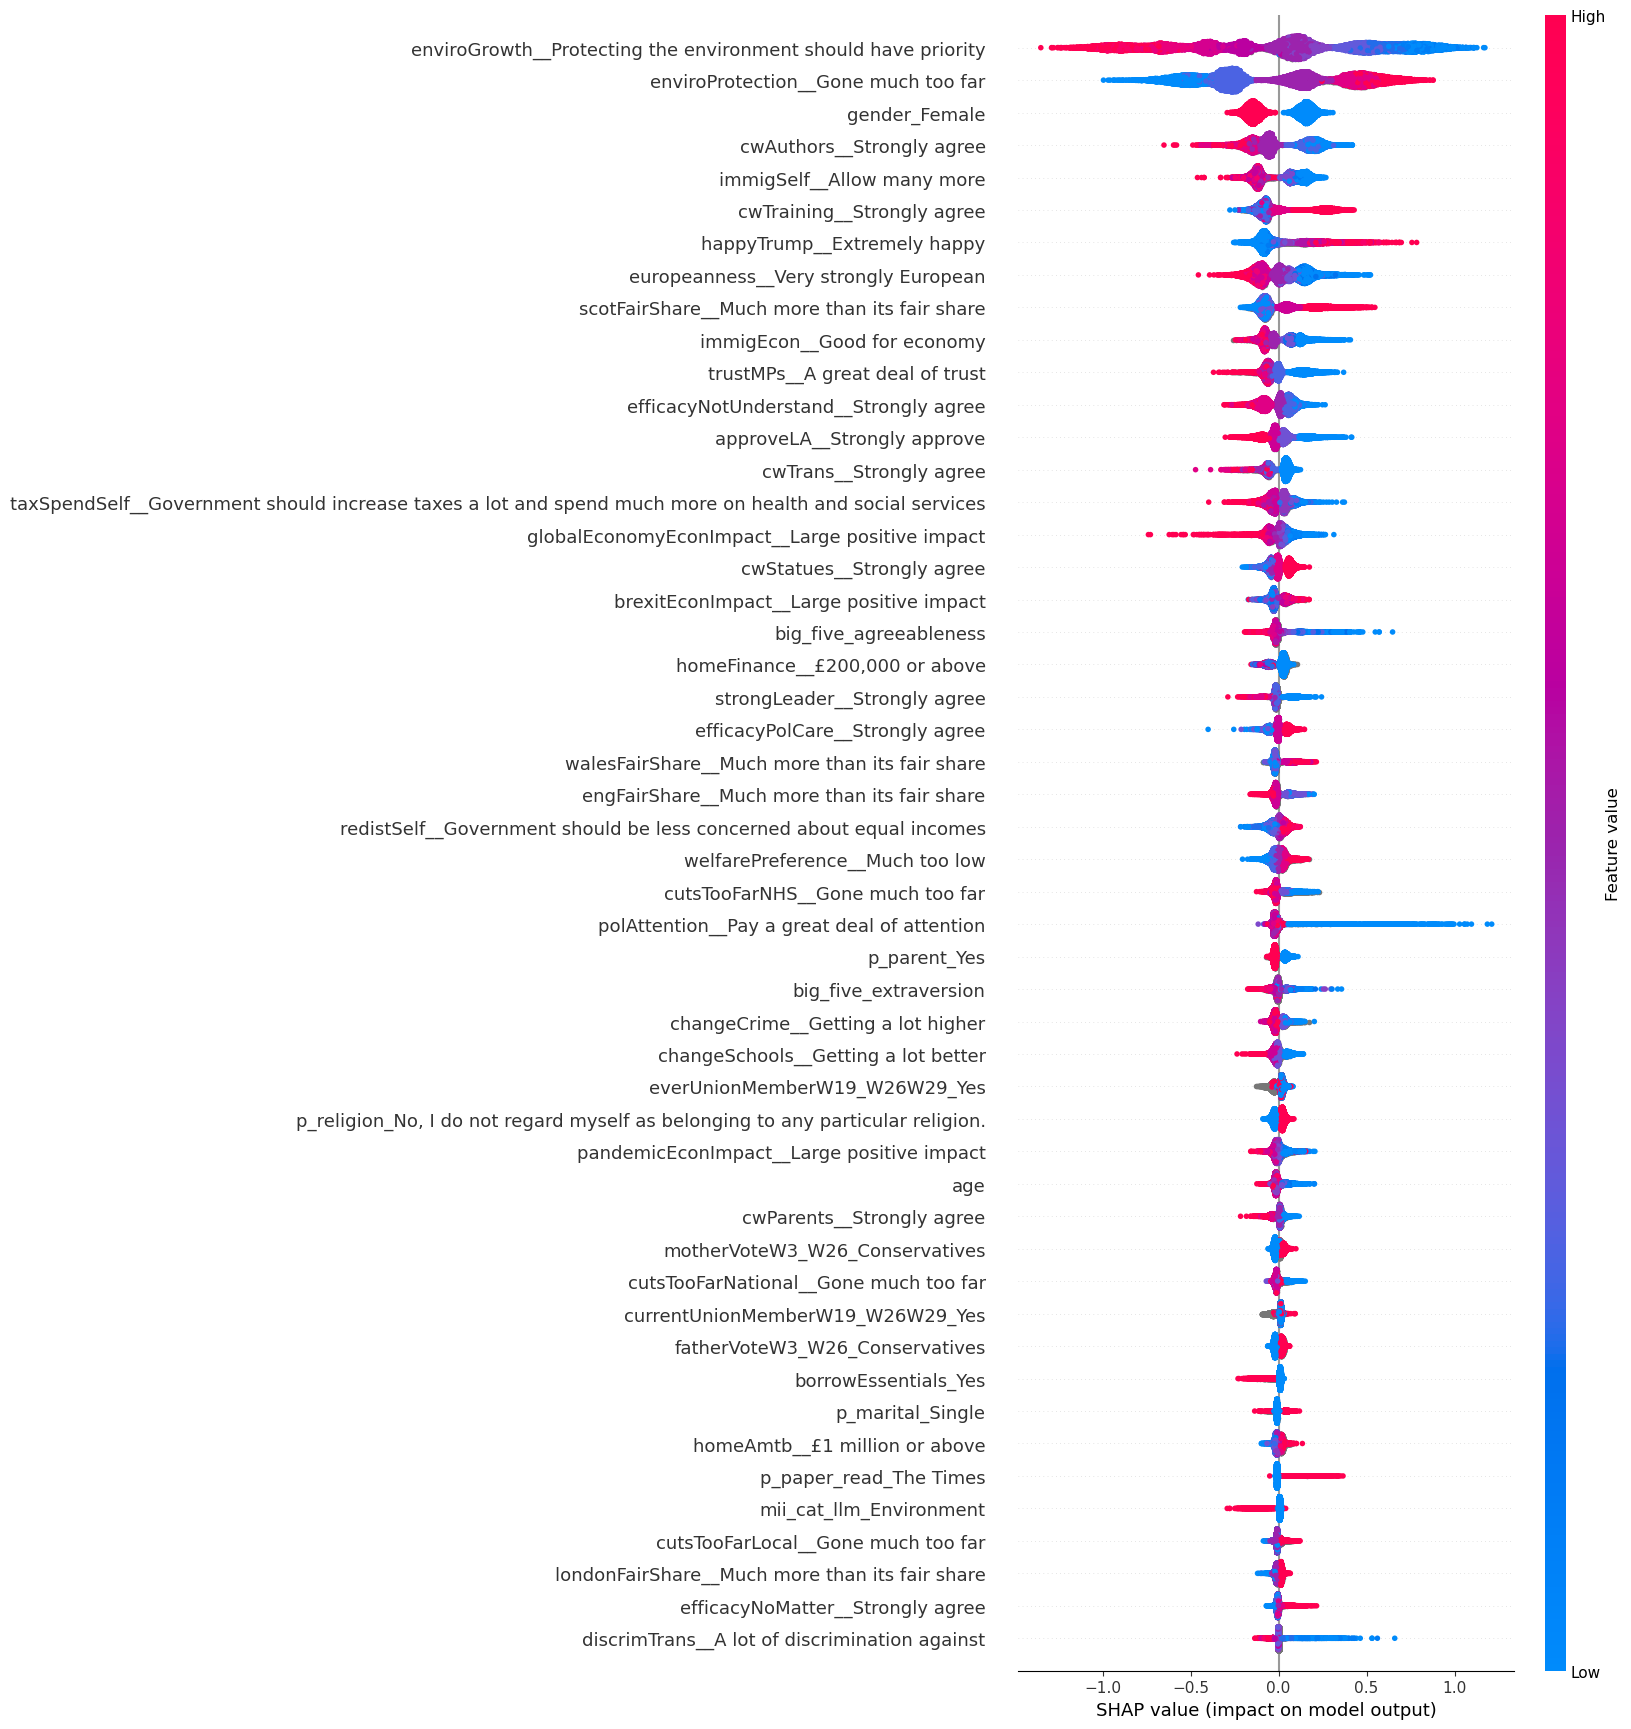

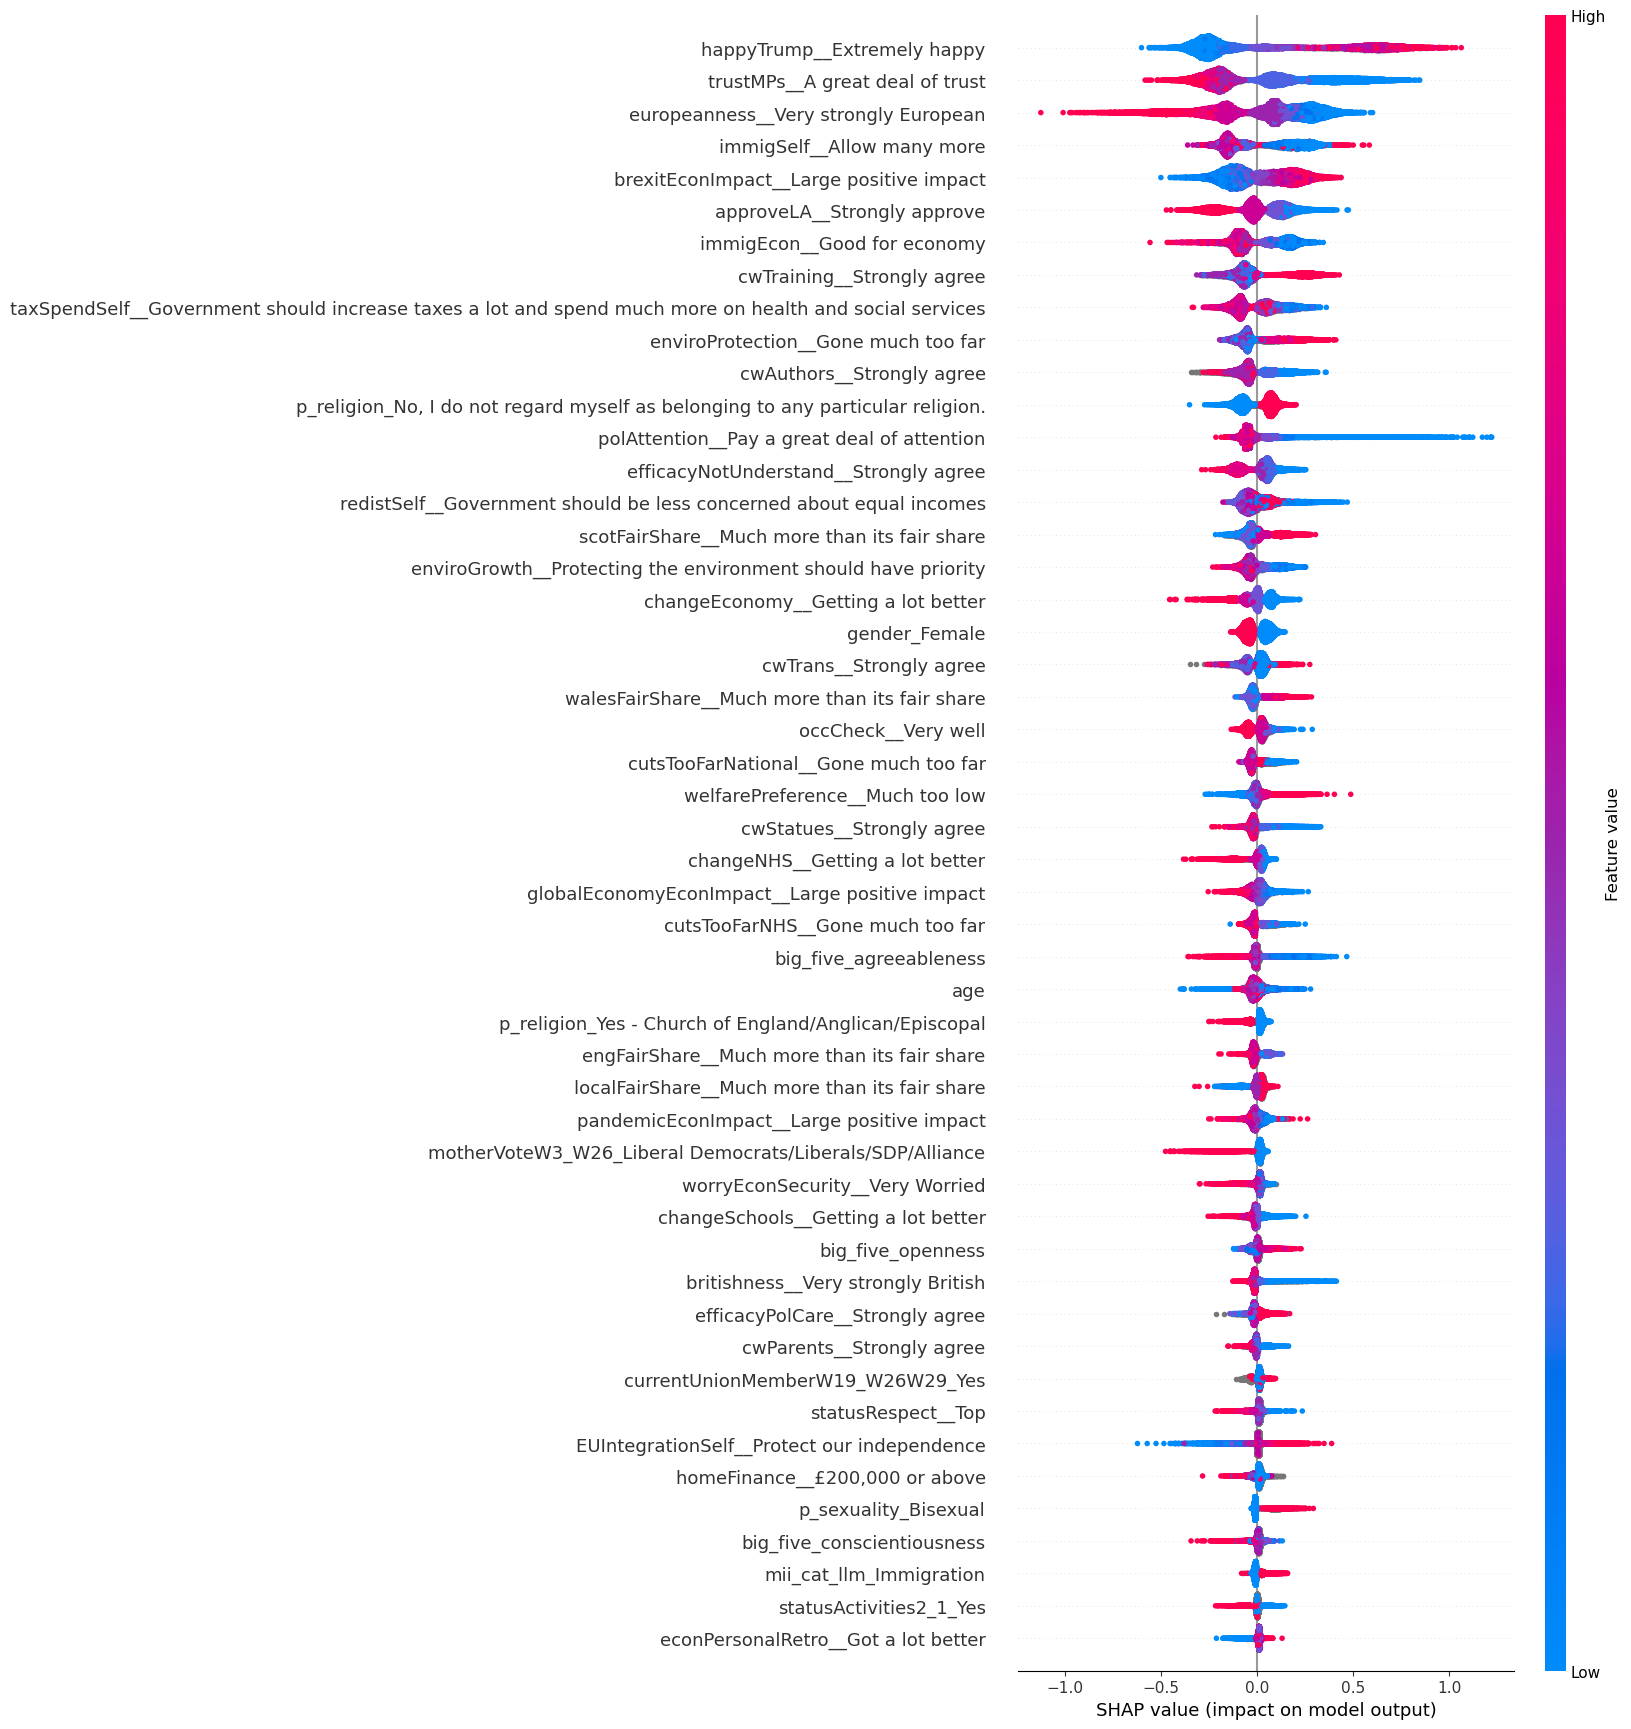

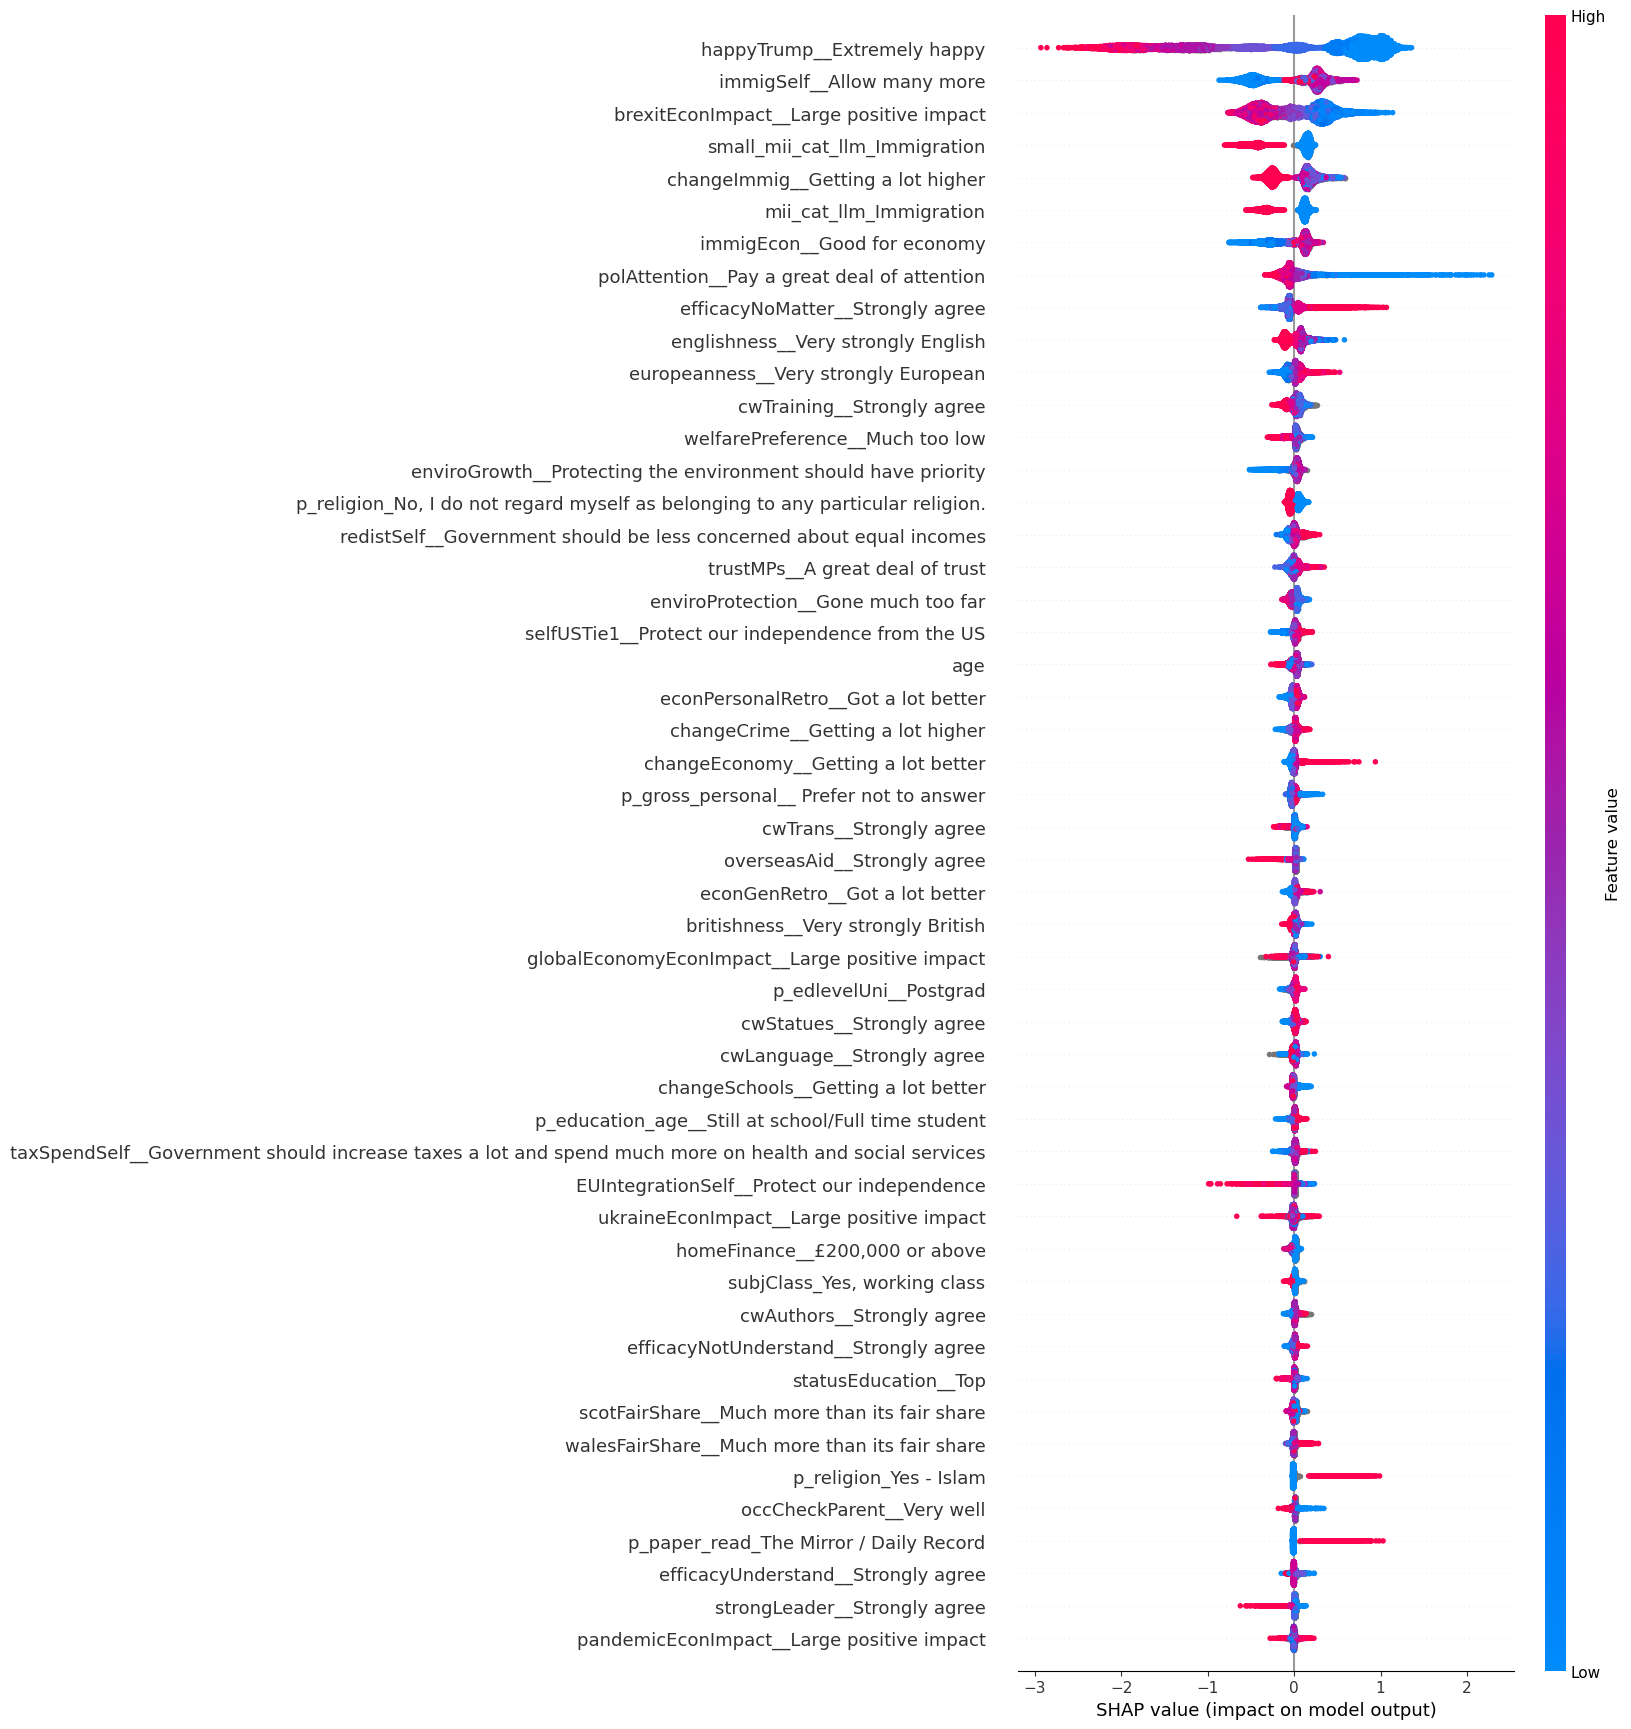

In [81]:
for party in ["Con","Lab","Grn","LD","BrexitParty"]:
    name = "fitted_like_gap"+party
    
    mask = (BES_Panel["country"]=="England")
    stub_vars =stub_vars + [name,"fitted"]#,"^lr(_scale|\d)","^al(_scale|\d)","like"]
    stub_list = search(BES_reduced_with_na,"|".join(stub_vars)).index
    # stub_list = [name,"fitted","lr_scale","al_scale"]
    
    (explainer, shap_values, train_columns, train_index, alg,output_subfolder,metrics) = xgboost_run(
        title = "Like/PTV Gap - "+party+" (England)",
        dataset=BES_reduced_with_na[mask],
    
                                                        var_list = [name],var_stub_list = stub_list,verbosity=0,
        # classification_problem=True,
    # class_names = GE2024.cat.categories,colour_list=colour_list,
        min_features=50)

In [97]:
search(BES_reduced_with_na,"disapprovalVote")

disapprovalVote_Conservative                     6999
disapprovalVote_Reform UK                        6999
disapprovalVote_Labour                           6999
disapprovalVote_Green Party                      6999
disapprovalVote_Liberal Democrat                 6999
disapprovalVote_Scottish National Party (SNP)    6999
disapprovalVote_Plaid Cymru                      6999
dtype: int64

In [96]:
# Imagine that you had a vote against – instead of for – a party at the General Election on July 4th. Which
# of the following parties would you have voted against in your constituency?

BES_Panel["disapprovalVote"].value_counts()

disapprovalVote
Conservative                     2254
Reform UK                        2115
Labour                           1769
Don't know                        700
Green Party                       311
Liberal Democrat                  283
Scottish National Party (SNP)     237
Other                              68
Plaid Cymru                        30
Name: count, dtype: int64

In [64]:
stub_list

Index(['lr1__Strongly agree', 'lr2__Strongly agree', 'lr3__Strongly agree',
       'lr4__Strongly agree', 'lr5__Strongly agree', 'al1__Strongly agree',
       'al2__Strongly agree', 'al3__Strongly agree', 'al4__Strongly agree',
       'al5__Strongly agree', 'lr_scale__Right', 'al_scale__Authoritarian',
       'al_scale_uni', 'lr_scale_uni', 'fitted_likeCon'],
      dtype='object')

In [ ]:
name = "prPreference_That every party's percentage of seats in parliament is the same as their percentage of the vote"

mask = (BES_Panel["country"].notnull())
stub_vars =[name]#,"^lr(_scale|\d)","^al(_scale|\d)","like"]
stub_list = search(BES_reduced_with_na,"|".join(stub_vars)).index
# stub_list = [name,"fitted","lr_scale","al_scale"]

(explainer, shap_values, train_columns, train_index, alg,output_subfolder,metrics) = xgboost_run(
    title = "Like/PTV Gap - "+party+" (England)",
    dataset=BES_reduced_with_na[mask],

                                                    var_list = [name],var_stub_list = stub_list,verbosity=0,
    # classification_problem=True,
# class_names = GE2024.cat.categories,colour_list=colour_list,
    min_features=50)

MSE: 0.18, MAE: 0.36, EV: 0.26, R2: 0.26


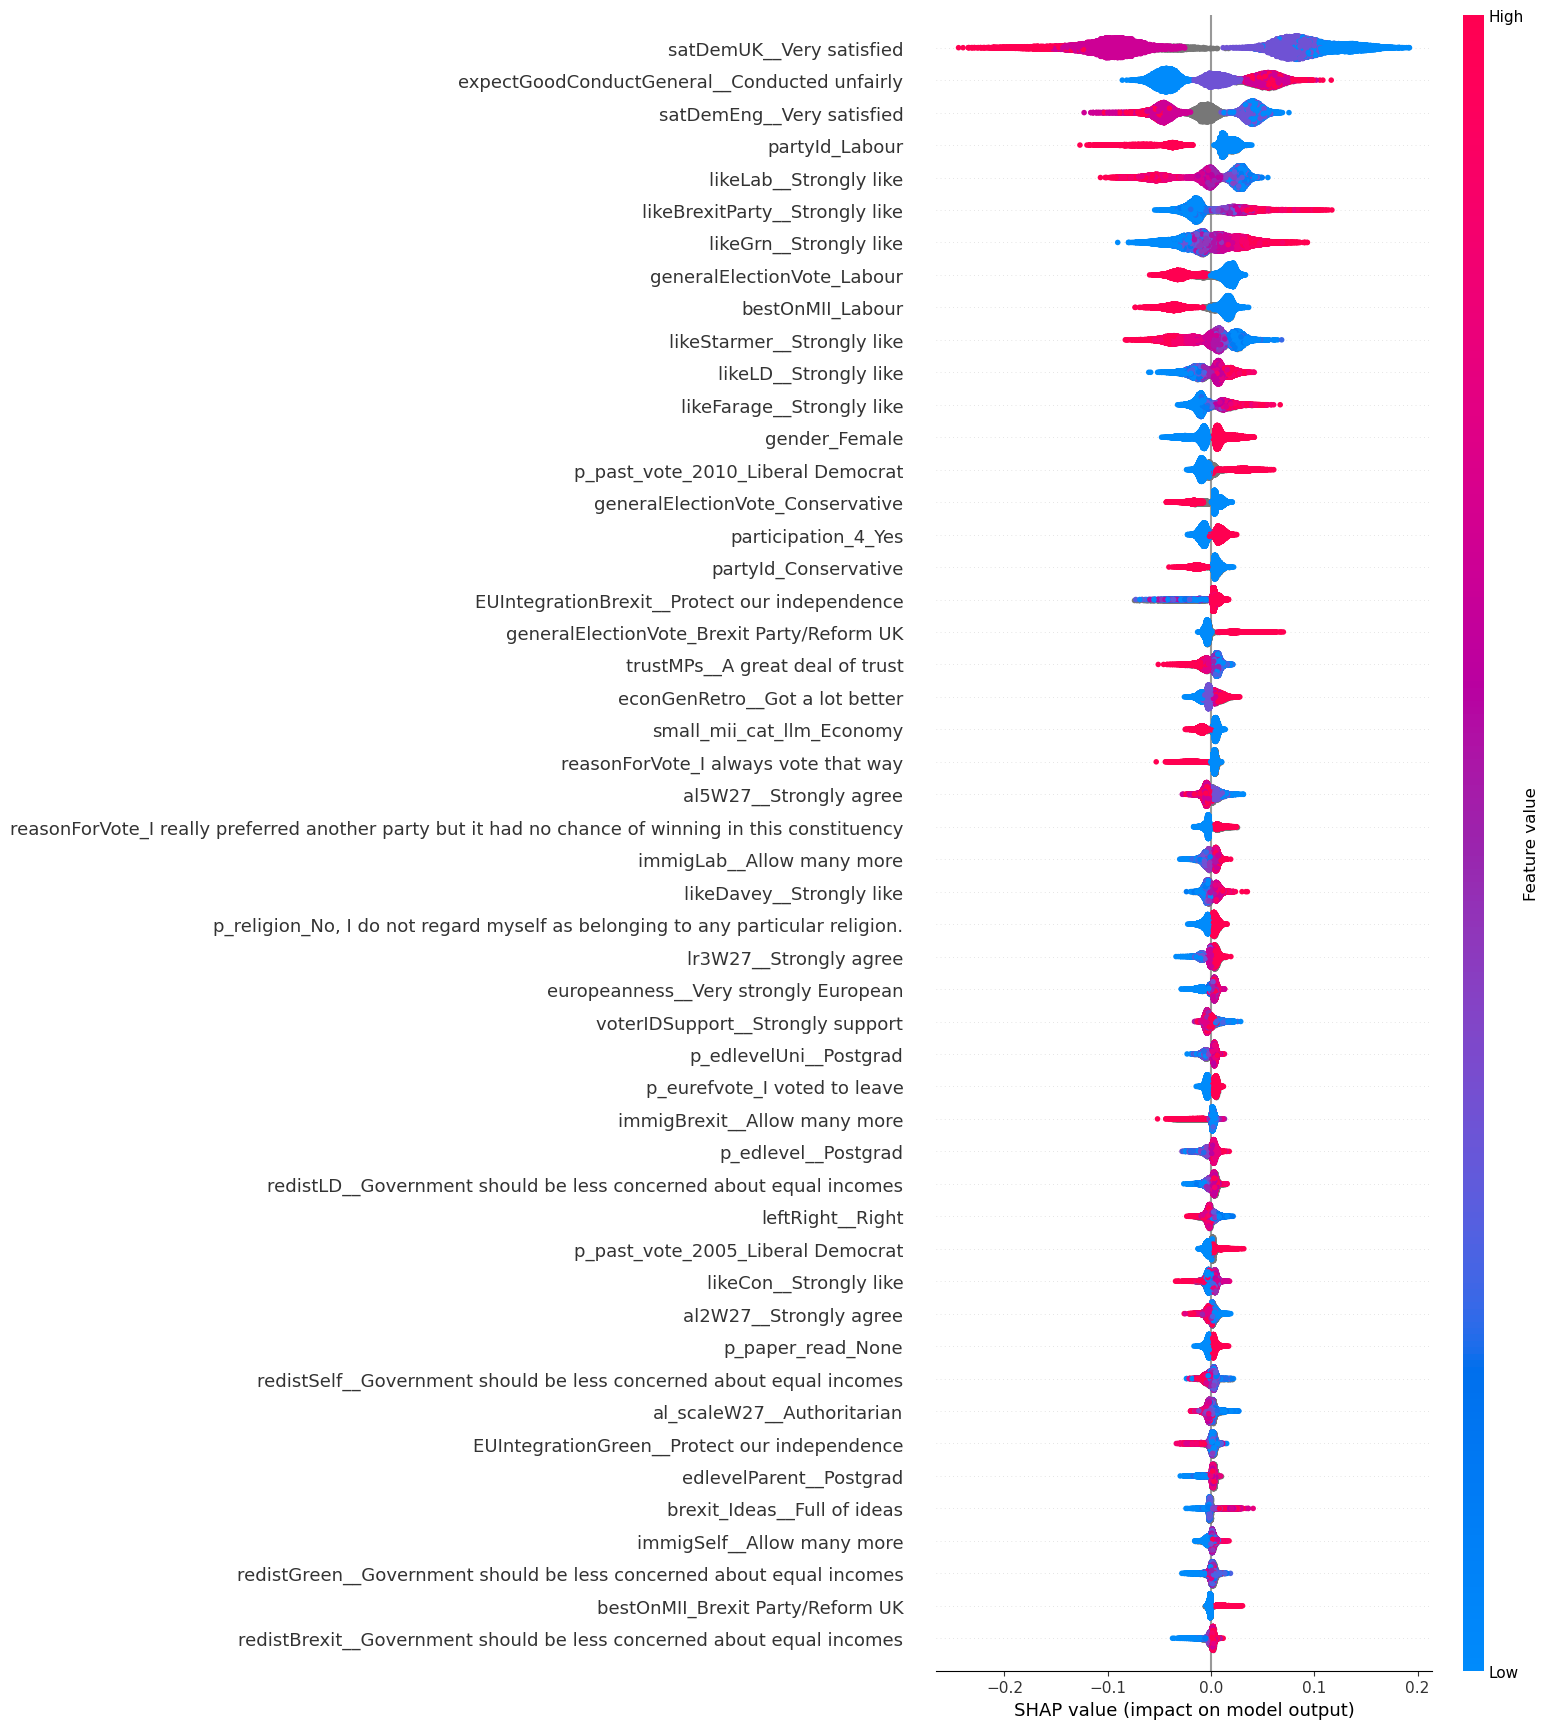

In [93]:
name = "prPreference_That every party's percentage of seats in parliament is the same as their percentage of the vote"

mask = (BES_Panel["country"].notnull())
stub_vars =[name]#,"^lr(_scale|\d)","^al(_scale|\d)","like"]
stub_list = search(BES_reduced_with_na,"|".join(stub_vars)).index
# stub_list = [name,"fitted","lr_scale","al_scale"]

(explainer, shap_values, train_columns, train_index, alg,output_subfolder,metrics) = xgboost_run(
    title = "Like/PTV Gap - "+party+" (England)",
    dataset=BES_reduced_with_na[mask],

                                                    var_list = [name],var_stub_list = stub_list,verbosity=0,
    # classification_problem=True,
# class_names = GE2024.cat.categories,colour_list=colour_list,
    min_features=50)

In [101]:
BES_Panel["disapprovalVote"].cat.categories

Index(['Conservative', 'Labour', 'Liberal Democrat',
       'Scottish National Party (SNP)', 'Plaid Cymru', 'Green Party', 'Other',
       'Reform UK', 'Don't know'],
      dtype='object')

ACC: 0.64,  F1: 0.64


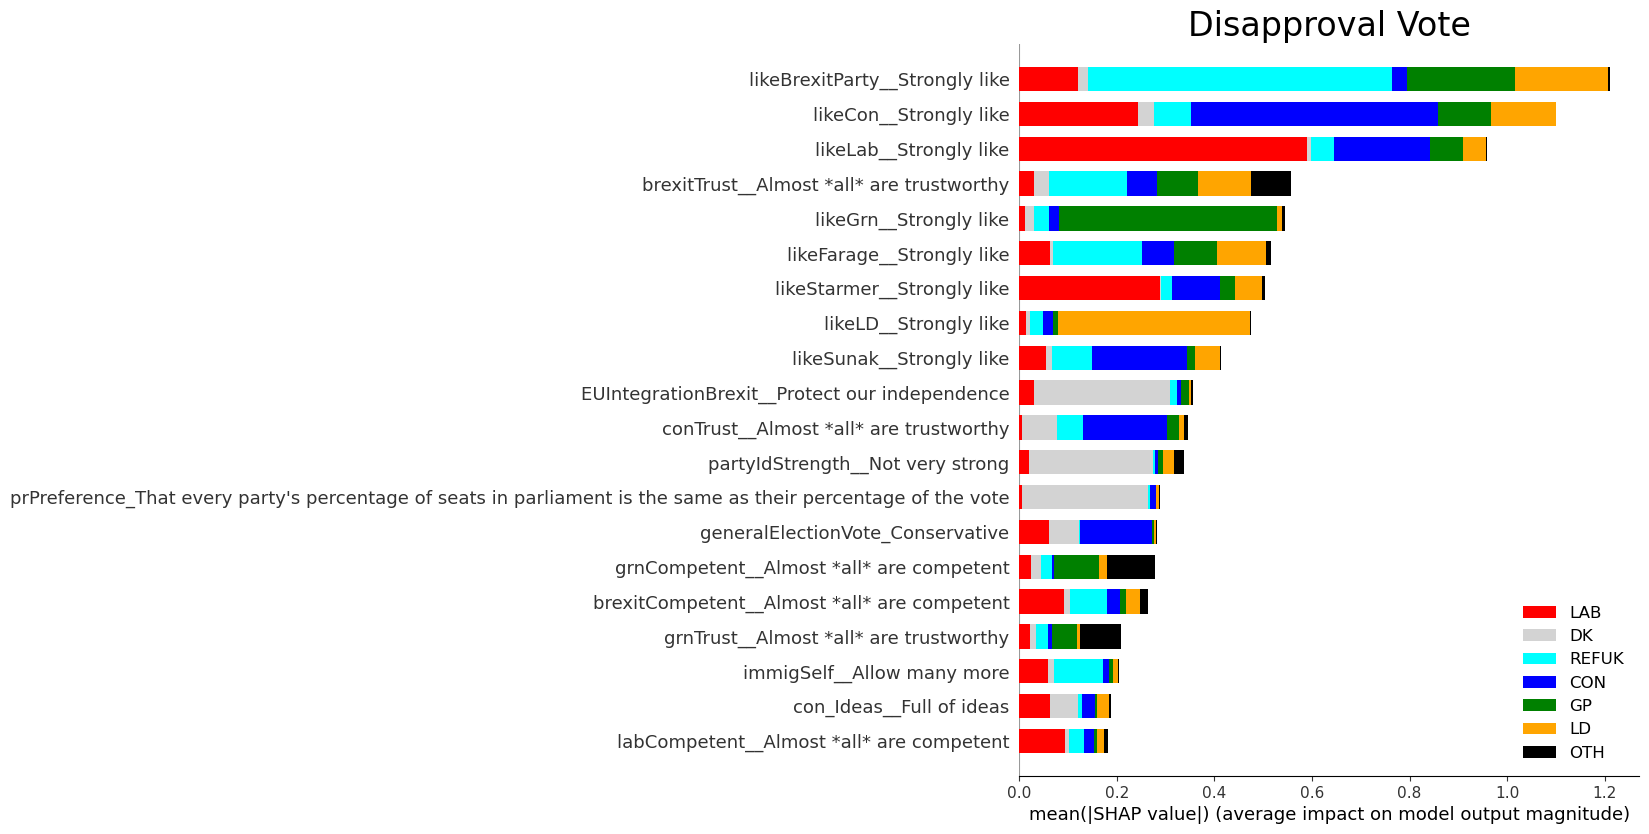

In [105]:
replace_dict = {'Conservative':"CON", 'Labour':"LAB", 'Liberal Democrat':"LD",
       'Scottish National Party (SNP)':np.nan, 'Plaid Cymru':np.nan, 'Green Party':"GP", 'Other':"OTH",
       'Reform UK':"REFUK", "Don't know":"DK"}

disapprovalVote = BES_Panel["disapprovalVote"].astype('object').replace(replace_dict).astype('category')

BES_reduced_with_na["disapprovalVote"]=disapprovalVote.cat.codes.replace(-1,np.nan).astype('category')
name = "disapprovalVote"
mask = (BES_Panel["country"]=="England") & BES_reduced_with_na[name].notnull()

party_colour_dict = {"CON":'blue',"LAB":'red',"GP":'green',"LD":'orange',"OTH":'black',"WNV":'darkgrey',"DNV":'darkgrey',
                     "REFUK":'cyan',"UKIP":'purple',"TIG":'pink',
                    "DK":"lightgrey","PC":'olive'}
stub_vars = ["disapprovalVote"]
stub_list = search(BES_reduced_with_na,"|".join(stub_vars)).index
colour_list = [party_colour_dict[x] for x in disapprovalVote.cat.categories]

(explainer, shap_values, train_columns, train_index, alg,output_subfolder,metrics) = xgboost_run(
    title = "How did people vote in GE2024?(England)",
    dataset=BES_reduced_with_na[mask],
                                                    var_list = [name],var_stub_list = stub_list,verbosity=0,classification_problem=True,
class_names = disapprovalVote.cat.categories,colour_list=colour_list,min_features=20,use_specific_weights=BES_Panel["wt"][mask])
plt.title("Disapproval Vote",fontsize=24);

ACC: 0.54,  F1: 0.54


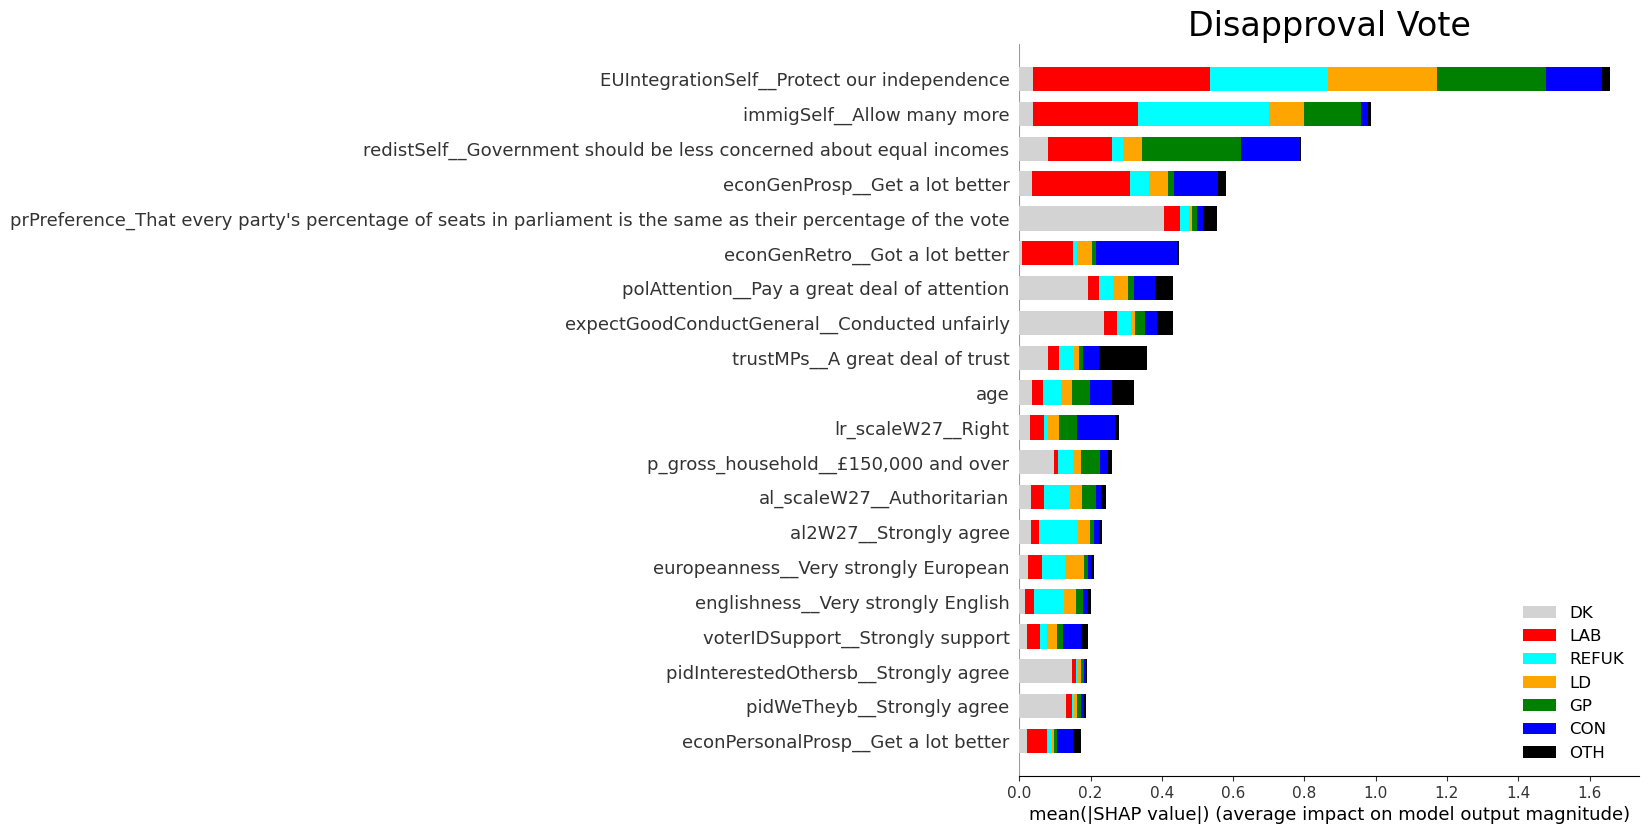

In [107]:
replace_dict = {'Conservative':"CON", 'Labour':"LAB", 'Liberal Democrat':"LD",
       'Scottish National Party (SNP)':np.nan, 'Plaid Cymru':np.nan, 'Green Party':"GP", 'Other':"OTH",
       'Reform UK':"REFUK", "Don't know":"DK"}

disapprovalVote = BES_Panel["disapprovalVote"].astype('object').replace(replace_dict).astype('category')

BES_reduced_with_na["disapprovalVote"]=disapprovalVote.cat.codes.replace(-1,np.nan).astype('category')
name = "disapprovalVote"
mask = (BES_Panel["country"]=="England") & BES_reduced_with_na[name].notnull()

party_colour_dict = {"CON":'blue',"LAB":'red',"GP":'green',"LD":'orange',"OTH":'black',"WNV":'darkgrey',"DNV":'darkgrey',
                     "REFUK":'cyan',"UKIP":'purple',"TIG":'pink',
                    "DK":"lightgrey","PC":'olive'}
# stub_vars = ["disapprovalVote"]
stub_list = search(BES_reduced_with_na,"|".join(stub_vars)).index
colour_list = [party_colour_dict[x] for x in disapprovalVote.cat.categories]

(explainer, shap_values, train_columns, train_index, alg,output_subfolder,metrics) = xgboost_run(
    title = "How did people vote in GE2024?(England)",
    dataset=BES_reduced_with_na[mask],
                                                    var_list = [name],var_stub_list = stub_list,verbosity=0,classification_problem=True,
class_names = disapprovalVote.cat.categories,colour_list=colour_list,min_features=20,use_specific_weights=BES_Panel["wt"][mask])
plt.title("Disapproval Vote",fontsize=24);

In [58]:

BES_Panel["p_past_vote_2024"][mask].value_counts()


BES_Panel["p_past_vote_2024"]#.replace(replace_dict)#.cat.remove_unused_categories()



id
18              Yes, I voted
24              Yes, I voted
30              Yes, I voted
31        No, I did not vote
33              Yes, I voted
                 ...        
123795    No, I did not vote
123796          Yes, I voted
123797          Yes, I voted
123798    No, I did not vote
123799          Yes, I voted
Name: p_turnout_2024, Length: 30342, dtype: category
Categories (3, object): ['No, I did not vote' < 'Yes, I voted' < 'Don't know']

In [60]:
replace_dict = {"Other":np.nan, "Scottish National Party (SNP)":np.nan, "An independent candidate":np.nan, "Don't know":np.nan,
                "Plaid Cymru":"PC", "Labour":"LAB", "Conservative":"CON", "Brexit Party/Reform UK":"REFUK", "Liberal Democrat":"LD",
                "Green Party":"GP",}
GE2024 = BES_Panel["p_past_vote_2024"].astype('object').replace(replace_dict)#.astype('category')
GE2024.loc[BES_Panel["p_turnout_2024"]=='No, I did not vote'] = "DNV"
GE2024 = GE2024.astype('category')
mask = BES_Panel["country"]=="Wales"
print(GE2024[mask].value_counts(dropna=False))
# mask = (BES_Panel["reasonForVote"]=="I thought it was the best party") & (BES_Panel["country"]=="England") & GE2024.notnull()
# mask.sum()
# BES_Panel["generalElectionVote"][mask].value_counts(dropna=False)

BES_reduced_with_na["GE2024"] = GE2024.cat.codes.replace(-1,np.nan).astype('category')

p_past_vote_2024
LAB      576
CON      269
DNV      257
REFUK    251
PC       250
LD       115
GP        82
NaN       71
Name: count, dtype: int64


ACC: 0.52,  F1: 0.52


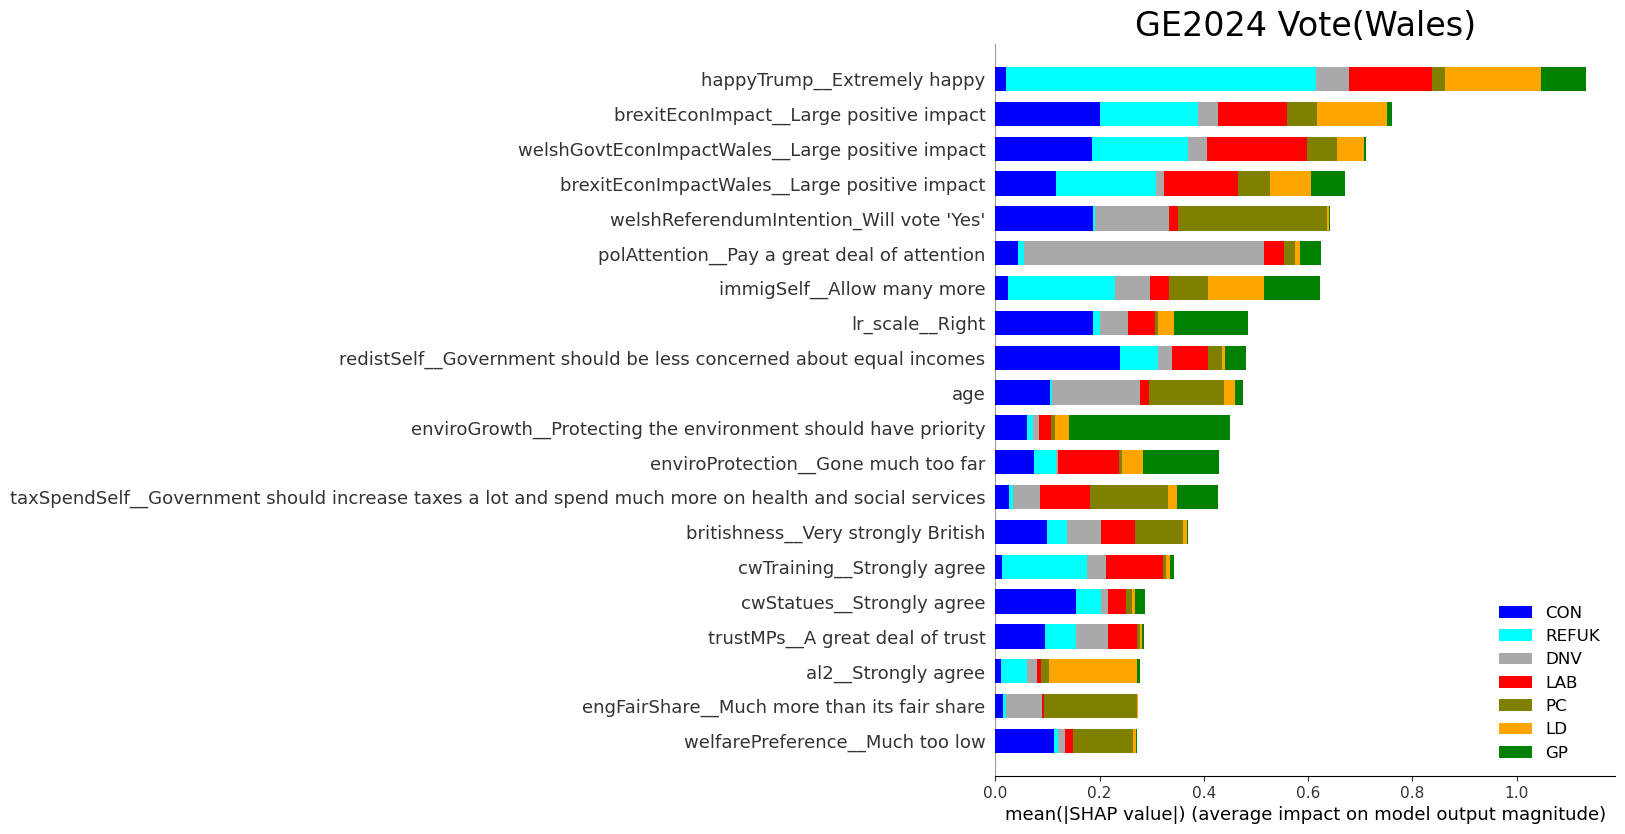

In [64]:
name = "GE2024"
# mask = BES_Panel["country"]=="England"

party_colour_dict = {"CON":'blue',"LAB":'red',"GP":'green',"LD":'orange',"OTH":'black',"WNV":'darkgrey',"DNV":'darkgrey',
                     "REFUK":'cyan',"UKIP":'purple',"TIG":'pink',
                    "DK":"lightgrey","PC":'olive'}
stub_list = search(BES_reduced_with_na,"|".join(stub_vars)).index
colour_list = [party_colour_dict[x] for x in GE2024.cat.categories]

(explainer, shap_values, train_columns, train_index, alg,output_subfolder,metrics) = xgboost_run(
    title = "How did people vote in GE2024?(England)",
    dataset=BES_reduced_with_na[mask],
                                                    var_list = [name],var_stub_list = stub_list,verbosity=0,classification_problem=True,
class_names = GE2024.cat.categories,colour_list=colour_list,min_features=20,use_specific_weights=BES_Panel["wt"][mask])
plt.title("GE2024 Vote(Wales)",fontsize=24);

In [44]:
BES_Panel["generalElectionVote"].astype('object').replace(replace_dict).value_counts()

generalElectionVote
REFUK    7226
LAB      5391
CON      3429
LD       3286
GP       2469
WNV      1554
PC        227
Name: count, dtype: int64

In [45]:
replace_dict = {"Other":np.nan,"Scottish National Party (SNP)":np.nan,"An independent candidate":np.nan,"Don't know":"DK",
                "Plaid Cymru":"PC","Labour":"LAB","Conservative":"CON","Brexit Party/Reform UK":"REFUK","Liberal Democrat":"LD",
               "Green Party":"GP","I would/did not vote":"WNV"}
VI2025 = BES_Panel["generalElectionVote"].astype('object').replace(replace_dict).astype('category')
print(VI2025[mask].value_counts(dropna=False))
# mask = (BES_Panel["reasonForVote"]=="I thought it was the best party") & (BES_Panel["country"]=="England") & GE2024.notnull()
# mask.sum()
# BES_Panel["generalElectionVote"][mask].value_counts(dropna=False)

BES_reduced_with_na["VI2025"] = VI2025.cat.codes.replace(-1,np.nan).astype('category')

generalElectionVote
REFUK    476
LAB      342
DK       275
PC       227
CON      167
LD       131
GP       111
WNV       90
NaN       52
Name: count, dtype: int64


In [66]:
GE2024.cat.categories

Index(['CON', 'DNV', 'GP', 'LAB', 'LD', 'PC', 'REFUK'], dtype='object')

In [68]:
VI2025.cat.categories

Index(['CON', 'DK', 'GP', 'LAB', 'LD', 'PC', 'REFUK', 'WNV'], dtype='object')

ACC: 0.51,  F1: 0.51


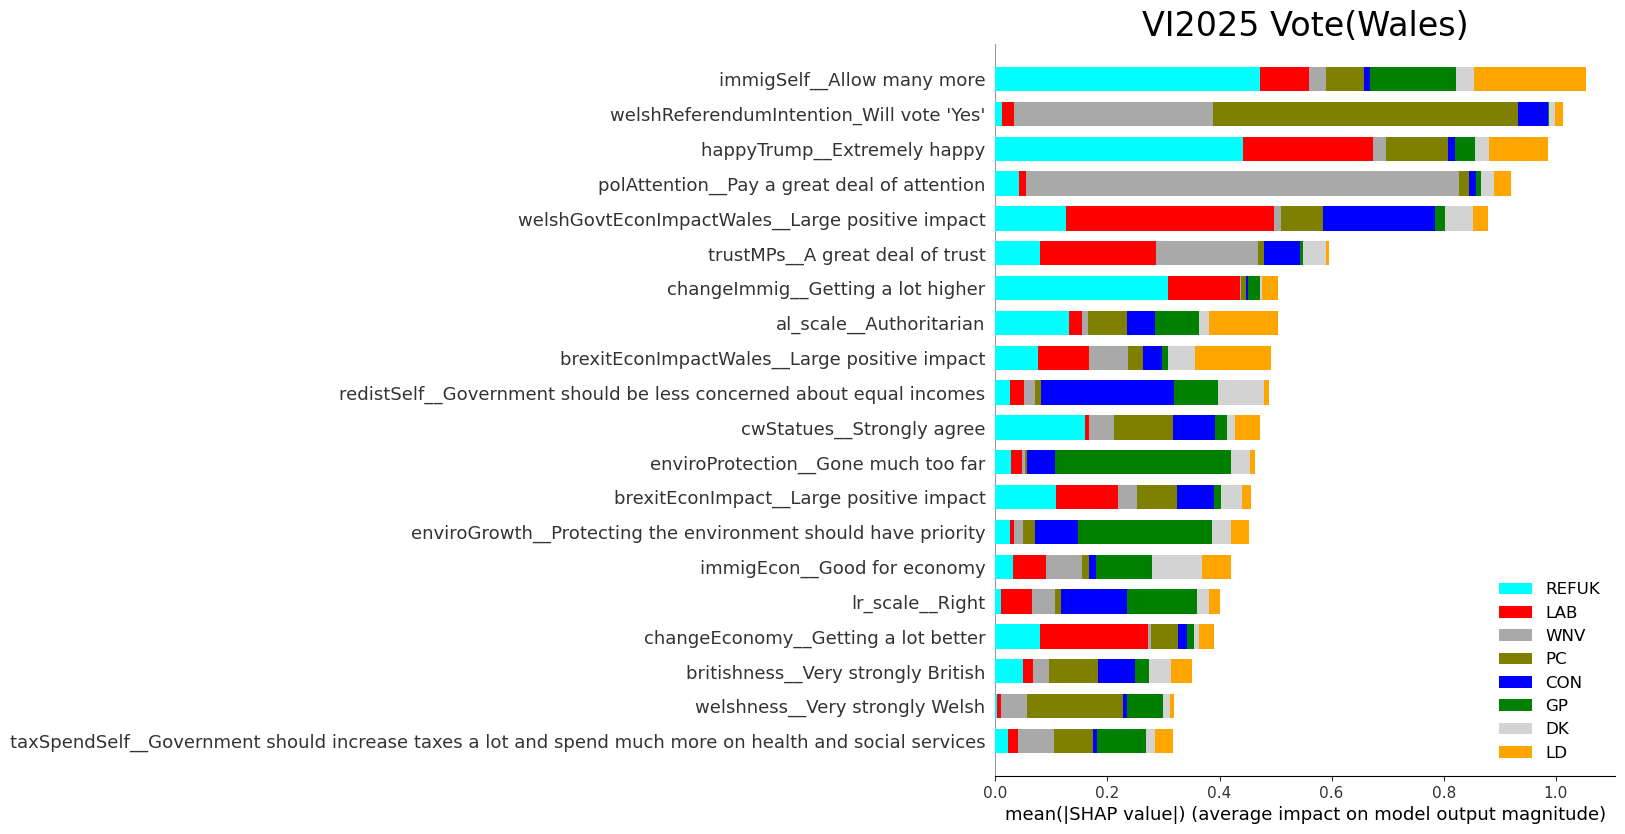

In [56]:
name = "VI2025"
# mask = BES_Panel["country"]=="England"

party_colour_dict = {"CON":'blue',"LAB":'red',"GP":'green',"LD":'orange',"OTH":'black',"WNV":'darkgrey',"REFUK":'cyan',"UKIP":'purple',"TIG":'pink',
                    "DK":"lightgrey","PC":'olive'}
stub_list = search(BES_reduced_with_na,"|".join(stub_vars)).index
colour_list = [party_colour_dict[x] for x in VI2025.cat.categories]

(explainer, shap_values, train_columns, train_index, alg,output_subfolder,metrics) = xgboost_run(
    title = "How did people vote in GE2024?(England)",
    dataset=BES_reduced_with_na[mask],
                                                    var_list = [name],var_stub_list = stub_list,verbosity=0,classification_problem=True,
class_names = VI2025.cat.categories,colour_list=colour_list,min_features=20,use_specific_weights=BES_Panel["wt"][mask])
plt.title("VI2025 Vote(Wales)",fontsize=24);

In [48]:
[party_colour_dict[x] for x in VI2025.cat.categories]

['blue', 'lightgrey', 'green', 'red', 'orange', 'olive', 'cyan', 'darkgrey']

In [33]:
search(BES_Panel,"p_welsh")

p_welsh_const_vote_2016    1898
p_welsh_list_vote_2016     1898
dtype: int64

In [24]:
GE2024.cat.categories

Index(['CON', 'GP', 'LAB', 'LD', 'PC', 'REFUK'], dtype='object')

In [26]:
colour_list

['blue', 'green', 'red', 'orange', 'olive', 'cyan']

In [ ]:
['blue', 'red', 'orange', 'green', 'cyan']

In [30]:
BES_reduced_with_na["GE2024"][mask].value_counts().sort_index()

GE2024
0.0    269
1.0     82
2.0    576
3.0    115
4.0    250
5.0    251
Name: count, dtype: int64

In [31]:
GE2024.cat.categories

Index(['CON', 'GP', 'LAB', 'LD', 'PC', 'REFUK'], dtype='object')

In [50]:
stub_list

Index(['turnoutUKGeneral__Very likely that I will vote',
       'partyIdStrength__Not very strong', 'likeBadenoch__Strongly like',
       'likeStarmer__Strongly like', 'likeDavey__Strongly like',
       'likeSwinney__Strongly like', 'likeFarage__Strongly like',
       'likeRamsay__Strongly like', 'likeDenyer__Strongly like',
       'likeCon__Strongly like',
       ...
       'localTurnoutRetro_Yes, voted', 'p_eurefvote_I voted to leave',
       'mayorTurnout_Yes, voted', 'p_turnout_2024_Yes, I voted',
       'p_turnout_2019_Yes, I voted', 'p_turnout_2017_Yes, I voted',
       'p_turnout_2015_Yes, I voted', 'askedForID_Yes', 'attemptTurnoutB_Yes',
       'euRefVoteAfter_Stay out of the EU'],
      dtype='object', length=252)